In [1]:
import heapq
import matplotlib.pyplot as plt
import numpy as np

class Node:
    def __init__(self, parent=None, position=None):
        self.parent = parent
        self.position = position

        self.g = 0
        self.h = 0
        self.f = 0

    def __eq__(self, other):
        return self.position == other.position

    def __lt__(self, other):
        return self.f < other.f

def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def astar(grid, start, end):
    start_node = Node(None, start)
    end_node = Node(None, end)

    open_list = []
    closed_set = set()

    heapq.heappush(open_list, start_node)

    while len(open_list) > 0:
        current_node = heapq.heappop(open_list)
        closed_set.add(current_node.position)

        if current_node == end_node:
            path = []
            current = current_node
            while current is not None:
                path.append(current.position)
                current = current.parent
            return path[::-1]

        (x, y) = current_node.position
        neighbors = [(x-1, y), (x+1, y), (x, y-1), (x, y+1)]

        for next_pos in neighbors:
            if next_pos[0] < 0 or next_pos[0] >= len(grid) or next_pos[1] < 0 or next_pos[1] >= len(grid[0]):
                continue

            if grid[next_pos[0]][next_pos[1]] != 0:
                continue

            if next_pos in closed_set:
                continue

            neighbor = Node(current_node, next_pos)
            neighbor.g = current_node.g + 1
            neighbor.h = heuristic(neighbor.position, end_node.position)
            neighbor.f = neighbor.g + neighbor.h

            if any(open_node for open_node in open_list if neighbor == open_node and neighbor.g > open_node.g):
                continue

            heapq.heappush(open_list, neighbor)

    return None

Path found: [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3), (4, 3), (4, 4), (4, 5), (5, 5), (6, 5), (7, 5), (7, 6)]


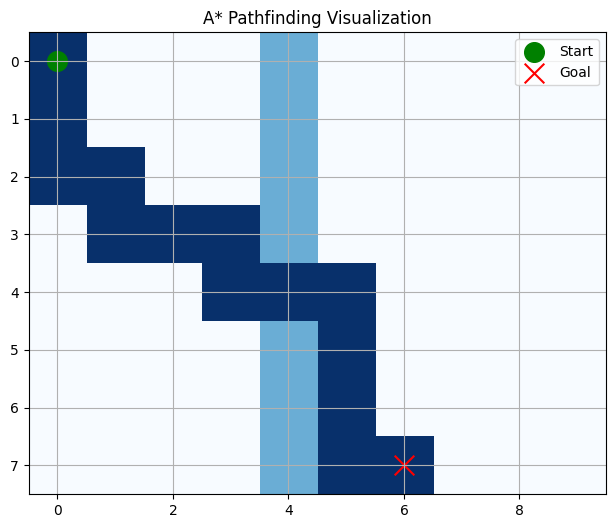

In [2]:
grid = [
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
]

start = (0, 0)
end = (7, 6)

path = astar(grid, start, end)
print("Path found:", path)

# Visualize the result
grid_array = np.array(grid)
if path:
    for p in path:
        grid_array[p[0]][p[1]] = 2

plt.figure(figsize=(8, 6))
plt.imshow(grid_array, cmap='Blues')
plt.scatter(start[1], start[0], color='green', marker='o', s=200, label='Start')
plt.scatter(end[1], end[0], color='red', marker='x', s=200, label='Goal')
plt.title("A* Pathfinding Visualization")
plt.legend()
plt.grid(True)
plt.show()